# การวิเคราะห์ปริมาณการเดินทางและผู้โดยสาร (ชุดข้อมูลที่ 4)
**รายวิชา:** AIE314 Data Preparation and Data Mining
**กลุ่ม:** Loading Brain... 1%
**Notebook:** 01 Data Preparation (ขั้นที่ 2 Data Quality Assessment ถึง ขั้นที่ 5 Export)

## โหลดข้อมูลดิบ

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "Tahoma"

DATA_DIR = "../data/"
df68_raw = pd.read_csv(DATA_DIR + "4_passengers68.csv", dtype=str)
df69_raw = pd.read_csv(DATA_DIR + "4_passengers69.csv", dtype=str)

# 2. Data Quality Assessment

*ขั้นนี้ตรวจและนับเพื่อเก็บหลักฐานอย่างเดียว ยังไม่แก้ข้อมูล การแก้ทำในขั้นที่ 3 ตามลำดับ ตรวจ → หลักฐาน → ตัดสินใจ → ตรวจผล (AIE315 W4)*

## 2.1 แถวว่างและแถวซ้ำ

*ตรวจแถวที่ว่างทุกคอลัมน์และแถวที่ซ้ำกัน เพราะแถวซ้ำทำให้ผลรวมและค่าเฉลี่ยผิด (AIE314 บทที่ 5 หน้า 5, 7, 18–19; AIE315 W6 สไลด์ 10)*

In [2]:
blank68 = df68_raw.isna().all(axis= 1)
blank69 = df69_raw.isna().all(axis= 1)

print(f"จำนวนเเถวที่ว่างปี 2568: {blank68.sum()} เเถว")
print(f"จำนวนเเถวที่ว่างปี 2569: {blank69.sum()} เเถว")
print('-'*100)

print(f"จำนวนเเถวที่ซ้ำ (รวมแถวว่าง): {df68_raw.duplicated().sum()} เเถว")
print('-'*100)

df68_check = df68_raw[~blank68]     # ~ = เลือกแถวที่ไม่ว่าง
dup_mask = df68_check.duplicated(keep= False)
print(f"เเถวที่เกี่ยวข้องกับการซ้ำ: {dup_mask.sum()} เเถว")
display(df68_check[dup_mask]) 
print('-'*100)

key_dup = df68_check.duplicated(subset=["ยานพาหนะ/ท่า", "วันที่"], keep= False)
print(f"บริการ + วันที่ซ้ำ: {key_dup.sum()} เเถว")
print(f"ปี 2569 ซ้ำ: {df69_raw.duplicated().sum()} เเถว" )

จำนวนเเถวที่ว่างปี 2568: 53744 เเถว
จำนวนเเถวที่ว่างปี 2569: 0 เเถว
----------------------------------------------------------------------------------------------------
จำนวนเเถวที่ซ้ำ (รวมแถวว่าง): 53744 เเถว
----------------------------------------------------------------------------------------------------
เเถวที่เกี่ยวข้องกับการซ้ำ: 2 เเถว


,รูปแบบการเดินทาง,วัตถุประสงค์,สาธารณะ/ส่วนบุคคล,หน่วยงาน,ยานพาหนะ/ท่า,วันที่,หน่วย,ปริมาณ
12641,ทางอากาศ,การเดินทางระหว่างประเทศ,สาธารณะ,ทย.,ท่าอากาศยานภูมิภาค ขาออกประเทศ,21/10/2025,คน,"1,257"
12642,ทางอากาศ,การเดินทางระหว่างประเทศ,สาธารณะ,ทย.,ท่าอากาศยานภูมิภาค ขาออกประเทศ,21/10/2025,คน,"1,257"


----------------------------------------------------------------------------------------------------
บริการ + วันที่ซ้ำ: 2 เเถว
ปี 2569 ซ้ำ: 0 เเถว


**ผลการตรวจ**
- แถวว่าง 53,744 แถว (ปี 68 เท่านั้น) เเละแถวซ้ำทุกคอลัมน์ 1 แถว: index 12642
- แถวว่างทั้งแถว 53,744 แถว อยู่ท้ายไฟล์ปี 68 ตั้งแต่ index 15,696 เป็นต้นไป ส่วนปี 69 ไม่มี
- ถ้าตรวจซ้ำบนข้อมูลดิบจะได้ 53,744 แถว เพราะแถวว่างซ้ำกันเอง 53,743 แถว จึงต้องตัดแถวว่างออกก่อนตรวจ
- หลังตัดแถวว่าง พบแถวซ้ำทุกคอลัมน์ 1 คู่ (index 12641–12642: ท่าอากาศยานภูมิภาค ขาออกประเทศ, 21/10/2025, 1,257 คน) ตรงกับที่คาดไว้ในข้อ 1.2 (15,696 − 15,695 = 1)
- ไม่พบบริการ+วันที่เดียวกันที่มีค่าขัดกัน จึงลบแถวซ้ำได้โดยไม่เสียข้อมูล
- การจัดการ: ลบในขั้นที่ 3

## 2.2 ชนิดข้อมูลและรูปแบบตัวเลข / วันที่

*รวมสองปีเป็นตารางตรวจเดียว พร้อมคอลัมน์ ไฟล์ เพื่อตามรอยที่มา (AIE315 W6 สไลด์ 9, 32) แล้วทดลองแปลงปริมาณเป็นตัวเลขและวันที่เป็น datetime ด้วย errors="coerce" เพื่อนับค่าที่แปลงไม่ได้ (AIE315 W5 สไลด์ 9–10)*

In [3]:
# รวมสองปีไว้ตรวจ (ตัดแถวว่างออกจากการตรวจ แต่ไม่แก้ต้นฉบับ)
df68_check = df68_raw[~blank68].copy()
df69_check = df69_raw.copy()
df68_check["ไฟล์"] = "4_passengers68.csv"
df69_check["ไฟล์"] = "4_passengers69.csv"
df_check = pd.concat([df68_check, df69_check], ignore_index= True)
print("ขนาดตารางที่ตรวจ: ", df_check.shape)
display(df_check.dtypes)
print('-'*100)

# ตรวจปริมาณ
qty_text = df_check["ปริมาณ"]
print("ค่าที่มีจุลภาค: ", qty_text.str.contains(",", regex= False).sum())
print('-'*100)

# ทดลองการเเปลง (เก็บในตัวแปรชั่วคราว ยังไม่แก้ตาราง)
qty_test = pd.to_numeric(
    qty_text.str.strip().str.replace(",","",regex= False),
    errors= "coerce"
)
print("ค่าว่างตั้งเเต่ต้น: ", qty_text.isna().sum())
print("เเปลงค่าไม่ได้ (ไม่นับค่าว่าง): ", (qty_test.isna() & qty_text.notna()).sum())
display(qty_test.describe().astype(int))
print('-'*100)

# ตรวจวันที่: ดูแบบข้อความก่อน
display(df_check.groupby("ไฟล์")["วันที่"].agg(["min","max"]))
print('-'*100)

# ตรวจวันที่: ทดลองแปลง โดยระบุรูปแบบ วัน/เดือน/ปี
date_test = pd.to_datetime(df_check["วันที่"], format= "%d/%m/%Y", errors= "coerce")
print("วันที่เเปลงไม่ได้: ", date_test.isna().sum())
print("ช่วงวันที่: ", date_test.min(), "ถึง", date_test.max())

ขนาดตารางที่ตรวจ:  (18706, 9)


รูปแบบการเดินทาง     str
วัตถุประสงค์         str
สาธารณะ/ส่วนบุคคล    str
หน่วยงาน             str
ยานพาหนะ/ท่า         str
วันที่               str
หน่วย                str
ปริมาณ               str
ไฟล์                 str
dtype: object

----------------------------------------------------------------------------------------------------
ค่าที่มีจุลภาค:  15069
----------------------------------------------------------------------------------------------------
ค่าว่างตั้งเเต่ต้น:  444
เเปลงค่าไม่ได้ (ไม่นับค่าว่าง):  0


count      18262
mean      166401
std       367837
min            0
25%         2205
50%        21861
75%        76847
max      3509191
Name: ปริมาณ, dtype: int64

----------------------------------------------------------------------------------------------------


,min,max
ไฟล์,,
4_passengers68.csv,01/01/2025,31/12/2025
4_passengers69.csv,01/01/2026,31/01/2026


----------------------------------------------------------------------------------------------------
วันที่เเปลงไม่ได้:  0
ช่วงวันที่:  2025-01-01 00:00:00 ถึง 2026-03-11 00:00:00


- ปริมาณ: เป็นข้อความทั้งหมด มีจุลภาค 15,069 ค่า แต่เมื่อลบจุลภาคแล้วแปลงได้ทุกค่า ยกเว้นค่าว่าง 444 ค่า ไม่มีค่าแปลก ๆ เช่น "-" หรือข้อความปน การแปลงจึงทำได้ปลอดภัย ส่วนค่าว่าง 444 ค่าจะตรวจละเอียดใน 2.3
- describe บอกปัญหาล่วงหน้า 2 เรื่อง:
  - min = 0 ต้องตรวจว่าเป็นศูนย์จริงหรือไม่ใช่ (2.4)
  - ช่วงค่ากว้างมาก ตั้งแต่ 0 ถึง 3.5 ล้าน เพราะรวมทุกบริการกับทั้งสองหน่วยไว้ด้วยกัน ค่าเฉลี่ยรวมนี้จึงไม่มีความหมาย ต้องดูแยกรายบริการ
- วันที่แบบข้อความเรียงผิด: ปี 69 แสดง max = 31/01/2026 ทั้งที่ข้อมูลจริงถึง 11/03/2026 เพราะการเทียบข้อความทำทีละตัวอักษร และ "3" ของ 31 มากกว่า "1" ของ 11 นี่คือหลักฐานว่าต้องแปลงเป็นวันที่ก่อนใช้งาน
- วันที่แบบระบุ format แปลงได้ครบ 0 error ช่วงข้อมูลคือ 1 ม.ค. 2025 ถึง 11 มี.ค. 2026

**แบบไม่ใส่อะไรเลย: pandas เดาว่าเป็น เดือน/วัน/ปี แล้วหยุดด้วย error ที่ "13/01/2025" เพราะไม่มีเดือนที่ 13**

**ถ้าใส่ errors="coerce" อย่างเดียว: ได้ NaT ถึง 9,504 ค่า และวันที่ที่เหลือบางค่าจะถูกอ่านสลับวันกับเดือน**

## 2.3 ค่าว่าง (Missing Values)

missing_pct = (จำนวนวันที่ว่าง ÷ จำนวนวันทั้งหมด) × 100

ประเภทการหายของข้อมูล (AIE315 Lab 2):
- MCAR: หายแบบสุ่ม ไม่เกี่ยวกับอะไร
- MAR: หายตามตัวแปรอื่นที่เราเห็น เช่น วันที่หรือหน่วยงาน
- MNAR: หายเพราะค่าของมันเอง

In [4]:
# ค่าว่างอยู่ในคอลัมน์ไหนบ้าง
display(df_check.isna().sum())
print("-"*100)

# สร้าง mask ว่าแถวไหนปริมาณว่าง
df_check["qty_missing"] = df_check["ปริมาณ"].isna()

# รวมรายบริการ แยกตามไฟล์: ว่างกี่วัน จากทั้งหมดกี่วัน
missing_report = (
    df_check.groupby(["ยานพาหนะ/ท่า", "ไฟล์"], as_index= False)
    .agg(missing_days= ("qty_missing", "sum"),
         total_days= ("qty_missing", "size"))
)
missing_report["missing_pct"] = (
    missing_report["missing_days"] / missing_report["total_days"] * 100
).round(1)

# แสดงเฉพาะบริการที่มีค่าว่าง
display(missing_report[missing_report["missing_days"] > 0]
        .sort_values("missing_days", ascending= False))
print("-"*100)

# แยกตามหน่วย
display(df_check.groupby("หน่วย")["qty_missing"].sum())
print("-"*100)

# ดูวันที่ของค่าว่างในกลุ่มหน่วย "คน"
person_missing = df_check["qty_missing"] & (df_check["หน่วย"] == "คน")
display(df_check.loc[person_missing, ["ยานพาหนะ/ท่า", "วันที่", "ไฟล์"]])
print("-"*100)

รูปแบบการเดินทาง       0
วัตถุประสงค์           0
สาธารณะ/ส่วนบุคคล      0
หน่วยงาน               0
ยานพาหนะ/ท่า           0
วันที่                 0
หน่วย                  0
ปริมาณ               444
ไฟล์                   0
dtype: int64

----------------------------------------------------------------------------------------------------


,ยานพาหนะ/ท่า,ไฟล์,missing_days,total_days,missing_pct
38,รถยนต์ทุกประเภท (10 จุดสำรวจ),4_passengers68.csv,143,365,39.2
42,รถยนต์เฉพาะ 4 ล้อ (10 จุดสำรวจ),4_passengers68.csv,143,365,39.2
39,รถยนต์ทุกประเภท (10 จุดสำรวจ),4_passengers69.csv,65,70,92.9
43,รถยนต์เฉพาะ 4 ล้อ (10 จุดสำรวจ),4_passengers69.csv,65,70,92.9
32,รถ บขส. ขาออกประเทศ,4_passengers68.csv,9,365,2.5
34,รถ บขส. ขาเข้าประเทศ,4_passengers68.csv,6,365,1.6
33,รถ บขส. ขาออกประเทศ,4_passengers69.csv,3,70,4.3
35,รถ บขส. ขาเข้าประเทศ,4_passengers69.csv,3,70,4.3
36,รถ บขส. และ รถร่วม,4_passengers68.csv,2,365,0.5
56,รถไฟ,4_passengers68.csv,1,365,0.3


----------------------------------------------------------------------------------------------------


หน่วย
คน      28
คัน    416
Name: qty_missing, dtype: int64

----------------------------------------------------------------------------------------------------


,ยานพาหนะ/ท่า,วันที่,ไฟล์
2480,รถ บขส. ขาเข้าประเทศ,27/02/2025,4_passengers68.csv
2481,รถ บขส. ขาออกประเทศ,27/02/2025,4_passengers68.csv
2867,รถ บขส. ขาเข้าประเทศ,08/03/2025,4_passengers68.csv
2868,รถ บขส. ขาออกประเทศ,08/03/2025,4_passengers68.csv
3899,รถ บขส. ขาเข้าประเทศ,01/04/2025,4_passengers68.csv
3900,รถ บขส. ขาออกประเทศ,01/04/2025,4_passengers68.csv
7770,รถ บขส. ขาออกประเทศ,30/06/2025,4_passengers68.csv
12371,รถ บขส. ขาออกประเทศ,15/10/2025,4_passengers68.csv
12542,รถ บขส. ขาเข้าประเทศ,19/10/2025,4_passengers68.csv
12543,รถ บขส. ขาออกประเทศ,19/10/2025,4_passengers68.csv


----------------------------------------------------------------------------------------------------


- ค่าว่าง 94% (416 จาก 444) อยู่ในรถยนต์ 10 จุดสำรวจ ซึ่งเป็นหน่วยคันที่โจทย์ห้ามรวมกับคนอยู่แล้ว ปี 69 ข้อมูลกลุ่มนี้มีแค่ 5 จาก 70 วัน จึงใช้เทียบปีในข้อ 2 ไม่ได้ (จะตัดสินใจจริงในขั้นที่ 3)
- หน่วยคนว่างแค่ 28 ค่า กระจายใน 8 บริการ ไม่เกิน 4.3% ต่อบริการ ผลกระทบต่อค่าเฉลี่ยรายบริการจึงน้อย
- ไม่ควรเติม 0 แทนค่าว่าง เพราะค่าว่างคือ "ไม่มีรายงาน" ไม่ใช่ "ไม่มีคนใช้" ถ้าเติม 0 ค่าเฉลี่ยจะต่ำลงผิด ๆ ข้อนี้จะเป็นหนึ่งในวิธีที่นำไปทดสอบในข้อ 2
- ประเภทการหาย (ต้องระวังไม่สรุปเกินหลักฐาน):
   - รถไฟฟ้า 4 สายว่างวันเดียวกัน ดูเป็นปัญหาการรายงานของวันนั้นมากกว่าเกิดแบบสุ่มทีละสาย ข้อนี้ใกล้ MAR (ขึ้นกับวันที่)
   - รถยนต์ 10 จุดสำรวจว่างเป็นช่วงยาว ก็ขึ้นกับช่วงเวลาเช่นกัน
   - ข้อมูลที่มีไม่พอจะยืนยันว่าเป็น MNAR เพราะต้องรู้ค่าที่หายไป ซึ่งเราไม่รู้

## 2.4 ค่า 0

*ค่า 0 มีสองความหมาย: ศูนย์จริง (ไม่มีผู้ใช้จริง) หรือ ไม่มีข้อมูล (หยุดรายงานแต่ระบบใส่ 0) แยกด้วยหลักฐาน 3 อย่าง: เป็น 0 ทั้งช่วงหรือบางวัน, ต่อเนื่องหรือกระจาย, และระดับปกติก่อนหน้า (ใช้มัธยฐาน AIE314 บทที่ 5 หน้า 24)*

span_days = (วันสุดท้ายที่เป็น 0 − วันแรกที่เป็น 0) + 1
  - ถ้า zero_days = span_days → เป็น 0 ต่อเนื่องทุกวันในช่วงนั้น
  - ถ้า zero_days < span_days → 0 กระจาย มีวันปกติแทรกอยู่

In [5]:
# นำผลแปลงจาก 2.2 มาใส่เป็นคอลัมน์ในตารางตรวจ

df_check["qty_test"] = qty_test
df_check["date_test"] = date_test

df_check["qty_zero"] = df_check["qty_test"] == 0
print("จำนวนค่า 0 ทั้งหมด: ", df_check["qty_zero"].sum())
print("-"*100)
display(df_check.groupby("หน่วย")["qty_zero"].sum())
print("-"*100)

# สรุปรายบริการ แยกไฟล์: เป็น 0 กี่วัน วันแรก/วันสุดท้าย
zero_report = (
    df_check[df_check["qty_zero"]]
    .groupby(["ยานพาหนะ/ท่า", "ไฟล์"], as_index= False)
    .agg(zero_days= ("qty_zero", "size"),
         first_zero= ("date_test", "min"),
         last_zero= ("date_test", "max"))
)

# ช่วงวันจากวันแรกถึงวันสุดท้ายที่เป็น 0 (นับรวมทั้งสองวัน)
zero_report["span_days"] = (zero_report["last_zero"] - zero_report["first_zero"]).dt.days + 1
display(zero_report.sort_values("zero_days", ascending= False))
print("-"*100)

# ระดับปกติของรถหมวด 3/4 ก่อนเดือน ต.ค. 2025
before_oct = df_check["date_test"] < "2025-10-01"
for name in ["รถหมวด 3", "รถหมวด 4"]:
    normal = df_check.loc[before_oct & (df_check["ยานพาหนะ/ท่า"] == name), "qty_test"].median()
    print(name, "ค่ามัธยฐานก่อน ต.ค. 2025: ", normal , "คน/วัน")
print("-"*100)


จำนวนค่า 0 ทั้งหมด:  793
----------------------------------------------------------------------------------------------------


หน่วย
คน     793
คัน      0
Name: qty_zero, dtype: int64

----------------------------------------------------------------------------------------------------


,ยานพาหนะ/ท่า,ไฟล์,zero_days,first_zero,last_zero,span_days
3,รถร่วม (หมวด 1),4_passengers68.csv,365,2025-01-01,2025-12-31,365
7,รถหมวด 4,4_passengers68.csv,97,2025-01-29,2025-12-31,337
5,รถหมวด 3,4_passengers68.csv,93,2025-01-29,2025-12-31,337
4,รถร่วม (หมวด 1),4_passengers69.csv,70,2026-01-01,2026-03-11,70
6,รถหมวด 3,4_passengers69.csv,70,2026-01-01,2026-03-11,70
8,รถหมวด 4,4_passengers69.csv,70,2026-01-01,2026-03-11,70
10,รถไฟ ขาออกประเทศ,4_passengers68.csv,5,2025-03-31,2025-10-21,205
11,รถไฟ ขาเข้าประเทศ,4_passengers68.csv,5,2025-03-31,2025-10-21,205
15,เรือคลองแสนแสบ,4_passengers68.csv,4,2025-04-12,2025-04-15,4
12,รถไฟฟ้า ARL,4_passengers68.csv,4,2025-01-16,2025-08-15,212


----------------------------------------------------------------------------------------------------
รถหมวด 3 ค่ามัธยฐานก่อน ต.ค. 2025:  4272.0 คน/วัน
รถหมวด 4 ค่ามัธยฐานก่อน ต.ค. 2025:  641.0 คน/วัน
----------------------------------------------------------------------------------------------------


จัดได้ 3 กลุ่มตามหลักฐาน (W4 สไลด์ 16)
1. กลุ่ม A: เป็น 0 ทั้งช่วง หรือ 0 ยาวต่อเนื่องจนจบข้อมูล → "ไม่มีข้อมูล" มีหลักฐานชัด
   - รถร่วม (หมวด 1): เป็น 0 ทุกวันตลอด 435 วัน ไม่เคยมีตัวเลขเลย บริการที่มีจริงไม่น่ามีผู้ใช้เป็น 0 ทุกวันทั้งปี
   - รถหมวด 3 และ 4: ปกติมี 4,272 และ 641 คน/วัน แล้วกลายเป็น 0 ทุกวันตั้งแต่ 1 ต.ค. 2025 จนสิ้นสุดข้อมูล ตรวจด้วยมือได้: ต.ค.–ธ.ค. = 31 + 30 + 31 = 92 วัน บวกปี 69 อีก 70 วัน = 162 วันติดกัน การลดจากหลักพันเป็นศูนย์ทันทีแล้วอยู่ที่ศูนย์ 5 เดือน เป็นลักษณะของการหยุดรายงานมากกว่าไม่มีคนใช้จริง
   - รวมกลุ่มนี้ = 435 + 162 + 162 = 759 ค่า
2. กลุ่ม B: 0 ต่อเนื่องสั้น ๆ ไม่กี่วัน (zero_days = span) → อาจเป็นศูนย์จริง "ยังยืนยันไม่ได้"
   - เรือคลองแสนแสบ 12–15 เม.ย. 4 วันติด
   - ท่าอากาศยานสมุยและอู่ตะเภา 1–2 พ.ย. วันเดียวกันทั้งสองแห่ง
   - รถไฟฟ้าสายสีชมพูและสีเหลือง 29–30 มี.ค.

*ข้อควรระวัง: เหตุผลที่อาจอธิบายได้ เช่น ช่วงสงกรานต์ หรือการปิดให้บริการชั่วคราวช่วงปลายเดือน มี.ค. 2025 มาจากความรู้นอกชุดข้อมูล ถ้าจะเขียนในรายงานต้องมีแหล่งอ้างอิง ไม่อย่างนั้นให้เขียนแค่ว่า "เป็น 0 ต่อเนื่องสั้น ๆ ไม่สามารถยืนยันจากข้อมูลได้ว่าปิดบริการจริงหรือไม่ได้รายงาน"*

3. กลุ่ม C: 0 กระจายเป็นวัน ๆ (zero_days < span) → "ยังยืนยันไม่ได้"

   - รถไฟระหว่างประเทศ 5 วัน (ขาเข้าและขาออกเป็น 0 วันเดียวกัน)
   - ARL 4 วัน, รถไฟ 2 วัน
   - ท่าอากาศยานภูมิภาคขาเข้า 1 วัน
   - รถหมวด 3 จำนวน 1 วัน และรถหมวด 4 จำนวน 5 วัน ก่อนเดือน ต.ค.

*กลุ่ม B + C รวม 34 ค่า (793 − 759) ซึ่งตรงกับที่โจทย์ข้อ 2 ต้องการพอดี เราจะทดสอบว่าถ้าถือ 34 ค่านี้เป็น "ศูนย์จริง" กับ "ไม่มีข้อมูล" ผลจะเปลี่ยนไหม*

## 2.5 ชื่อไม่สอดคล้อง หน่วย และการนับซ้อน

ตรวจ 3 เรื่อง:
1. ช่องว่างเกินและชื่อที่สะกดไม่ตรงกัน
2. แต่ละบริการใช้หน่วยเดียวจริงไหม
3. ความสอดคล้องของข้อมูลชุดย่อย (Consistency): รถ 4 ล้อนับรวมอยู่ในรถทุกประเภท จึงต้องเป็นจริงทุกวันว่า 4 ล้อ ≤ ทุกประเภท

car4_share = รถ 4 ล้อ ÷ รถทุกประเภท (ค่าที่ถูกต้องต้องอยู่ระหว่าง 0 ถึง 1)

In [6]:
# ช่องว่างเกินหน้า/หลังในคอลัมน์ข้อความ
text_cols = ["รูปแบบการเดินทาง", "วัตถุประสงค์", "สาธารณะ/ส่วนบุคคล", "หน่วยงาน", "ยานพาหนะ/ท่า", "หน่วย"]

for col in text_cols:
    n_space = (df_check[col] != df_check[col].str.strip()).sum()
    print(col, ":",n_space)
print("-"*100)

# ชื่อท่าอากาศยานทั้งหมด ดูว่าสะกดตรงกันไหม
airport_mask = df_check["ยานพาหนะ/ท่า"].str.contains("ท่าอากาศ", regex= False)
display(df_check.loc[airport_mask, "ยานพาหนะ/ท่า"].value_counts())
print("-"*100)

# แต่ละบริการมีหน่วยกี่แบบ (ต้องเป็น 1)
print("จำนวนหน่วยสูงสุด/บริการ: ", df_check.groupby("ยานพาหนะ/ท่า")["หน่วย"].nunique().max())
print("-"*100)

# 3) รถ 4 ล้อ ต้อง ≤ รถทุกประเภท (ตรวจที่ทางด่วน)
car4 = df_check[df_check["ยานพาหนะ/ท่า"] == "รถยนต์เฉพาะ 4 ล้อ (ทางด่วน)"][["date_test", "qty_test"]]
all_cars = df_check[df_check["ยานพาหนะ/ท่า"] == "รถยนต์ทุกประเภท (ทางด่วน)"][["date_test", "qty_test"]]

# จับคู่ตามวันที่: ได้ qty_test_x = 4 ล้อ, qty_test_y = ทุกประเภท
car_pair = pd.merge(car4, all_cars, on= "date_test", how= "left", validate= "many_to_one")
car_pair["car4_share"] = car_pair["qty_test_x"] / car_pair["qty_test_y"]

print("ค่ามัธยฐานของสัดส่วน 4 ล้อ: ", car_pair["car4_share"].median().round(3))
print("-"*100)
bad_days = car_pair["qty_test_x"] > car_pair["qty_test_y"]
print("วันที่ 4 ล้อ > ทุกประเภท: ", bad_days.sum(), "วัน")
show = car_pair[bad_days].copy()
show["car4_share"] = show["car4_share"].round(3)
display(show)

รูปแบบการเดินทาง : 0
วัตถุประสงค์ : 0
สาธารณะ/ส่วนบุคคล : 0
หน่วยงาน : 0
ยานพาหนะ/ท่า : 0
หน่วย : 0
----------------------------------------------------------------------------------------------------


ยานพาหนะ/ท่า
ท่าอากาศยานภูมิภาค ขาออกประเทศ             436
ท่าอากาศยานสุวรรณภูมิ                      435
ท่าอากาศยานดอนเมือง                        435
ท่าอากาศอื่น ๆ ของ ทอท.                    435
ท่าอากาศยานภูมิภาค                         435
ท่าอากาศยานอู่ตะเภา                        435
ท่าอากาศยานสมุย                            435
ท่าอากาศยานสุวรรณภูมิ ขาเข้าประเทศ         435
ท่าอากาศยานสุวรรณภูมิ ขาออกประเทศ          435
ท่าอากาศยานดอนเมือง ขาเข้าประเทศ           435
ท่าอากาศยานดอนเมือง ขาออกประเทศ            435
ท่าอากาศยานอื่น ๆ ของ ทอท. ขาเข้าประเทศ    435
ท่าอากาศยานอื่น ๆ ของ ทอท. ขาออกประเทศ     435
ท่าอากาศยานภูมิภาค ขาเข้าประเทศ            435
Name: count, dtype: int64

----------------------------------------------------------------------------------------------------
จำนวนหน่วยสูงสุด/บริการ:  1
----------------------------------------------------------------------------------------------------
ค่ามัธยฐานของสัดส่วน 4 ล้อ:  0.962
----------------------------------------------------------------------------------------------------
วันที่ 4 ล้อ > ทุกประเภท:  5 วัน


,date_test,qty_test_x,qty_test_y,car4_share
0,2025-01-01,1364992.0,979129.0,1.394
1,2025-01-02,1286160.0,947189.0,1.358
29,2025-01-30,1641282.0,1517654.0,1.081
30,2025-01-31,1689391.0,1399387.0,1.207
282,2025-10-10,2373044.0,2301447.0,1.031


In [7]:
# ตรวจแบบเดียวกันที่ 10 จุดสำรวจ เพื่อดูว่าปัญหาเกิดเฉพาะทางด่วนหรือไม่
car4_10 = df_check[df_check["ยานพาหนะ/ท่า"] == "รถยนต์เฉพาะ 4 ล้อ (10 จุดสำรวจ)"][["date_test", "qty_test"]]
all_cars_10 = df_check[df_check["ยานพาหนะ/ท่า"] == "รถยนต์ทุกประเภท (10 จุดสำรวจ)"][["date_test", "qty_test"]]

car_pair_10 = pd.merge(car4_10, all_cars_10, on= "date_test", how= "left", validate= "many_to_one")
car_pair_10["car4_share"] = car_pair_10["qty_test_x"] / car_pair_10["qty_test_y"]

print("จำนวนวันที่มีตัวเลขครบทั้งคู่: ", car_pair_10["car4_share"].notna().sum(), "จาก", len(car_pair_10), "วัน")
print("ค่ามัธยฐานของสัดส่วน 4 ล้อ: ", car_pair_10["car4_share"].median().round(3))
print("วันที่ 4 ล้อ > ทุกประเภท: ", (car_pair_10["qty_test_x"] > car_pair_10["qty_test_y"]).sum(), "วัน")

จำนวนวันที่มีตัวเลขครบทั้งคู่:  227 จาก 435 วัน
ค่ามัธยฐานของสัดส่วน 4 ล้อ:  0.843
วันที่ 4 ล้อ > ทุกประเภท:  0 วัน


1. ไม่มีปัญหาช่องว่างเกิน
2. ชื่อสะกดผิด 435 แถว ต้องแก้เป็น ท่าอากาศยานอื่น ๆ ของ ทอท. ในขั้นที่ 3 แต่ละรายการยังเป็นคนละบริการกัน (ในประเทศกับระหว่างประเทศ) groupby จึงยังไม่ผิดตอนนี้ แต่ควรแก้เพื่อให้ความหมายตรงกัน
3. หน่วยสอดคล้อง: แต่ละบริการใช้หน่วยเดียว จึงแยกคน/คันได้ด้วยคอลัมน์ หน่วย อย่างปลอดภัย
4. การนับซ้อน:
    - รถ 4 ล้อเป็นส่วนหนึ่งของรถทุกประเภท ห้ามนำมาบวกกัน ถ้าต้องการปริมาณรถรวม ใช้ "ทุกประเภท" อย่างเดียว
    - ทางด่วนมี 5 วันที่ 4 ล้อมากกว่าทุกประเภท ซึ่งเป็นไปไม่ได้ ตัวเลขอย่างน้อยหนึ่งตัวในวันนั้นผิด แต่ข้อมูลไม่บอกว่าตัวไหน
    - 10 จุดสำรวจไม่พบวันที่ขัดกัน (0 วัน จาก 227 วันที่มีตัวเลขครบทั้งคู่ สัดส่วนมัธยฐาน 0.843) ปัญหานี้จึงเกิดเฉพาะที่ทางด่วน
    - ทางด่วน (กทพ.) กับ 10 จุดสำรวจ (ทล.) เป็นคนละจุดวัด ไม่ควรรวมกัน เพราะรถคันเดียวกันอาจผ่านทั้งสองจุด
5. แถวในประเทศกับระหว่างประเทศของท่าอากาศยานเดียวกัน แยกกันด้วย วัตถุประสงค์ ข้อ 3 จะใช้เฉพาะแถวระหว่างประเทศ จึงไม่นับซ้อน

### สรุปขั้นที่ 2: ตารางปัญหาคุณภาพข้อมูล

| # | ปัญหา | จำนวน | หลักฐาน | แนวทางจัดการ (ขั้นที่ 3) |
| :---: | :--- | ---: | :--- | :--- |
| 1 | แถวว่างทั้งแถว | 53,744 | ท้ายไฟล์ปี 2568 | ลบแถวว่าง |
| 2 | แถวซ้ำทุกคอลัมน์ | 1 | Index 12642 | ลบแถวซ้ำ โดยเก็บแถวแรก |
| 3 | ปริมาณเป็นข้อความที่มี `,` | 15,069 | สามารถแปลงเป็นตัวเลขได้ทั้งหมด | ลบ `,` แล้วแปลงเป็นตัวเลข |
| 4 | วันที่เป็นข้อความ dd/mm/yyyy | ทุกแถว | การหา Min/Max แบบข้อความให้ผลผิดพลาด | แปลงเป็น `datetime` |
| 5 | ค่าว่างในปริมาณ | 444 | หน่วยคัน 416, หน่วยคน 28 | เก็บเป็น `NaN` ไม่เติม 0 |
| 6 | ค่า 0 ที่เป็นการหยุดรายงาน | 759 | รถร่วมหมวด 1 ทั้งช่วง และรถหมวด 3/4 ตั้งแต่ 1 ต.ค. 2025 | เปลี่ยนเป็น `NaN` |
| 7 | ค่า 0 ที่ยังยืนยันไม่ได้ | 34 | ค่า 0 ในช่วงสั้น ๆ หรือกระจาย | ยังไม่แก้ไข ใช้ทดสอบในข้อ 2 |
| 8 | ชื่อสะกดผิด | 435 | ขาดคำว่า "ยาน" | แก้ไขชื่อให้ถูกต้อง |
| 9 | 4 ล้อ > ทุกประเภท (ทางด่วน) | 5 วัน | ขัดกับนิยามของข้อมูลชุดย่อย | พิจารณาแนวทางจัดการในขั้นที่ 3 |
| 10 | หน่วยคน/คัน และการนับซ้อน | 4 บริการ | รถยนต์เป็นหน่วยคัน | แยกวิเคราะห์ตามหน่วย ไม่รวมกับหน่วยคน |

# 3. Data Cleaning

*ขั้นนี้แก้ปัญหาตามแนวทางในตารางสรุปขั้นที่ 2 บนตารางใหม่ df โดยไม่แก้ข้อมูลดิบ ทุกการแก้ต้องแสดงตัวเลขก่อน/หลัง เพื่อเป็นหลักฐานผลกระทบ ตามลำดับ ตรวจ → หลักฐาน → ตัดสินใจ → ตรวจผล (AIE315 W4)*

## 3.1 รวมไฟล์ ลบแถวว่าง/ซ้ำ แก้ชื่อ และแปลงชนิดข้อมูล

*แก้ปัญหาข้อ 1–4 และ 8 จากตารางสรุปขั้นที่ 2 โดยสร้างตารางใหม่ df ไม่แก้ข้อมูลดิบ (AIE315 W4 สไลด์ 17, W6 สไลด์ 32)*

จำนวนแถวที่ต้องได้ = 43 × 365 + 43 × 70 = 15,695 + 3,010 = 18,705

In [8]:
# เก็บชื่อ 8 คอลัมน์เดิม ไว้ใช้ตรวจแถวว่าง
raw_cols = df68_raw.columns.tolist()

# รวมสองไฟล์ พร้อมคอลัมน์ ไฟล์ ไว้ตามรอย
df68 = df68_raw.copy()
df69 = df69_raw.copy()
df68["ไฟล์"] = "4_passengers68.csv"
df69["ไฟล์"] = "4_passengers69.csv"
df = pd.concat([df68, df69], ignore_index= True)
print("จำนวนเเถวหลังรวมสองไฟล์: ", len(df), "แถว")
print("-"*100)

# ลบแถวว่างทั้งแถว (ดูเฉพาะ 8 คอลัมน์เดิม เพราะคอลัมน์ ไฟล์ ไม่มีวันว่าง)
df = df.dropna(how= "all", subset= raw_cols)
print("จำนวนเเถวหลังลบแถวว่าง: ", len(df), "แถว")
print("-"*100)

# ลบแถวซ้ำทุกคอลัมน์ เก็บแถวแรกไว้
df = df.drop_duplicates()
print("จำนวนแถวหลังลบแถวซ้ำ: ", len(df), "แถว")
print("-"*100)

# แก้ชื่อสะกดผิด (ขาดคำว่า "ยาน")
old_name = "ท่าอากาศอื่น ๆ ของ ทอท."
new_name = "ท่าอากาศยานอื่น ๆ ของ ทอท."
print("ชื่อผิดก่อนแก้: ", (df["ยานพาหนะ/ท่า"] == old_name).sum(), "เเถว")
df["ยานพาหนะ/ท่า"] = df["ยานพาหนะ/ท่า"].replace(old_name, new_name)
print("ชื่อผิดหลังแก้: ", (df["ยานพาหนะ/ท่า"] == old_name).sum(), "แถว")
print("-"*100)

# แปลงชนิดข้อมูล: สร้างคอลัมน์ใหม่ ไม่ทับคอลัมน์เดิม
df["qty"] = pd.to_numeric(
    df["ปริมาณ"].str.strip().str.replace(",","", regex= False),
    errors= "coerce"
)
df["date"] = pd.to_datetime(df["วันที่"], format= "%d/%m/%Y", errors= "coerce")
print("qty ว่าง: ", df["qty"].isna().sum(), "| date แปลงไม่ได้: ", df["date"].isna().sum())
print("-"*100)

# ตรวจผล: 1 แถว = 1 บริการ × 1 วัน
display(df.groupby("ไฟล์").size())
print("จำนวนวัน/บริการ: ", df.groupby(["ยานพาหนะ/ท่า", "ไฟล์"]).size().unique())
print("บริการ + วันที่ซ้ำ: ", df.duplicated(subset= ["ยานพาหนะ/ท่า", "date"]).sum())


จำนวนเเถวหลังรวมสองไฟล์:  72450 แถว
----------------------------------------------------------------------------------------------------
จำนวนเเถวหลังลบแถวว่าง:  18706 แถว
----------------------------------------------------------------------------------------------------
จำนวนแถวหลังลบแถวซ้ำ:  18705 แถว
----------------------------------------------------------------------------------------------------
ชื่อผิดก่อนแก้:  435 เเถว
ชื่อผิดหลังแก้:  0 แถว
----------------------------------------------------------------------------------------------------
qty ว่าง:  444 | date แปลงไม่ได้:  0
----------------------------------------------------------------------------------------------------


ไฟล์
4_passengers68.csv    15695
4_passengers69.csv     3010
dtype: int64

จำนวนวัน/บริการ:  [365  70]
บริการ + วันที่ซ้ำ:  0


- ลบแถวว่าง 53,744 แถว และแถวซ้ำ 1 แถว เหลือ 18,705 แถว ตรงกับ 43 × 365 + 43 × 70 พอดี
- ทุกบริการมี 365 วัน (ปี 68) และ 70 วัน (ปี 69) ไม่มีบริการ + วันที่ซ้ำ จึงยืนยันได้ว่า 1 แถว = 1 บริการ × 1 วัน
- แก้ชื่อสะกดผิด 435 แถว เหลือ 0
- qty แปลงได้ทุกค่า ค่าว่าง 444 ค่าคือค่าว่างเดิม ยังเก็บเป็น NaN ไม่เติม 0 (ตามข้อ 5 ของตารางสรุป)
- date แปลงได้ครบ ไม่มีค่าผิด

## 3.2 เเกัค่า 0

*แก้ปัญหาข้อ 6–7 จากตารางสรุปขั้นที่ 2: ค่า 0 กลุ่ม A (หยุดรายงาน) เปลี่ยนเป็น NaN ส่วนกลุ่ม B/C (ยังยืนยันไม่ได้) เก็บค่า 0 ไว้ และทำเครื่องหมายในคอลัมน์ zero_unconfirmed เพื่อใช้ทดสอบในข้อ 2 (AIE315 W4 สไลด์ 16, 18)*


- ค่า 0 หลังแก้ = 0 ก่อนแก้ − กลุ่ม A
- ค่า 0 หลังแก้ = 793 − 759 = 34
- NaN หลังแก้ = NaN ก่อนแก้ + กลุ่ม A
- ค่าว่างหลังแก้ = 444 + 759 = 1,203

In [9]:
# ตัวเลขก่อนแก้
print("ค่า 0 ก่อนแก้: ", (df["qty"] == 0).sum(), "| ค่าว่างก่อนแก้: ", df["qty"].isna().sum())
print("-"*100)

# กลุ่ม A: 0 ที่เป็นการหยุดรายงาน (หลักฐานจาก 2.4)
service = df["ยานพาหนะ/ท่า"]
stop_all = service == "รถร่วม (หมวด 1)"                                    # 0 ตลอดทั้งช่วง
stop_oct = ((service == "รถหมวด 3") | (service == "รถหมวด 4")) & (df["date"] >= "2025-10-01")   # 0 ตั้งแต่ 1 ต.ค. 2025
group_a = (stop_all | stop_oct) & (df["qty"] == 0)
print("กลุ่ม A (ไม่มีข้อมูล): ", group_a.sum(), "ค่า")

# กลุ่ม B/C: 0 ที่เหลือ ยังยืนยันไม่ได้ ทำเครื่องหมายไว้ใช้ในข้อ 2
df["zero_unconfirmed"] = (df["qty"] == 0) & ~group_a
print("กลุ่ม B/C (ยังยืนยันไม่ได้): ", df["zero_unconfirmed"].sum(), "ค่า")
print("-"*100)

# แก้กลุ่ม A ให้เป็น NaN
df.loc[group_a, "qty"] = np.nan

# ตรวจผล
print("ค่า 0 หลังแก้: ", (df["qty"] == 0).sum(), "| ค่าว่างหลังแก้: ", df["qty"].isna().sum())
print("-"*100)
display(df[df["qty"].isna()].groupby("หน่วย").size())
print("-"*100)
display(df[df["zero_unconfirmed"]].groupby("ยานพาหนะ/ท่า").size())

ค่า 0 ก่อนแก้:  793 | ค่าว่างก่อนแก้:  444
----------------------------------------------------------------------------------------------------
กลุ่ม A (ไม่มีข้อมูล):  759 ค่า
กลุ่ม B/C (ยังยืนยันไม่ได้):  34 ค่า
----------------------------------------------------------------------------------------------------
ค่า 0 หลังแก้:  34 | ค่าว่างหลังแก้:  1203
----------------------------------------------------------------------------------------------------


หน่วย
คน     787
คัน    416
dtype: int64

----------------------------------------------------------------------------------------------------


ยานพาหนะ/ท่า
ท่าอากาศยานภูมิภาค ขาเข้าประเทศ    1
ท่าอากาศยานสมุย                    2
ท่าอากาศยานอู่ตะเภา                2
รถหมวด 3                           1
รถหมวด 4                           5
รถไฟ                               2
รถไฟ ขาออกประเทศ                   5
รถไฟ ขาเข้าประเทศ                  5
รถไฟฟ้า ARL                        4
รถไฟฟ้าสายสีชมพู                   2
รถไฟฟ้าสายสีเหลือง                 1
เรือคลองแสนแสบ                     4
dtype: int64

- เปลี่ยนค่า 0 กลุ่ม A 759 ค่าเป็น NaN ค่า 0 ลดจาก 793 เหลือ 34 และค่าว่างเพิ่มจาก 444 เป็น 1,203 ตรงกับที่คิดมือ
- ค่าว่างที่เพิ่มเป็นหน่วยคนทั้งหมด (28 → 787) หน่วยคันยังเป็น 416 เท่าเดิม
- ค่า 0 ที่เหลือ 34 ค่า กระจายใน 12 บริการ ยังไม่แก้ และทำเครื่องหมายไว้ในคอลัมน์ zero_unconfirmed เพื่อใช้ทดสอบความไวในข้อ 2
- ผลกระทบ: ค่าเฉลี่ยรถหมวด 3/4 ตั้งแต่ ต.ค. 2025 จะคำนวณจากวันที่มีข้อมูลเท่านั้น ไม่ถูกดึงลงด้วย 0 ที่ไม่ใช่ตัวเลขจริง

## 3.3 Outlier

*หา outlier ด้วย IQR แยกรายบริการ (ขนาดแต่ละบริการต่างกันมาก จึงใช้รั้วเดียวกันทั้งตารางไม่ได้) แล้วติดสถานะตามหลักฐาน แก้เฉพาะค่าที่ยืนยันว่าผิด ไม่ cap หรือตัด outlier ทั้งหมด เพราะข้อ 1 และข้อ 3 ต้องใช้ค่าสูง/ต่ำที่เกิดขึ้นจริง (AIE315 W4 สไลด์ 9–10, 16, 18)*

IQR = Q3 − Q1, รั้วล่าง = Q1 − 1.5 × IQR, รั้วบน = Q3 + 1.5 × IQR
ratio_to_median = qty ÷ มัธยฐานของบริการ (1 = วันปกติ)

outlier ทั้งหมด:  258 ค่า
----------------------------------------------------------------------------------------------------


ยานพาหนะ/ท่า
เรือไฟฟ้าเจ้าพระยา                 51
รถ บขส. และ รถร่วม                 25
รถ บขส. ขาเข้าประเทศ               23
ท่าอากาศยานภูมิภาค ขาเข้าประเทศ    21
รถไฟ                               16
เรือข้ามฟากเจ้าพระยา               15
รถ บขส. ขาออกประเทศ                13
รถไฟ ขาออกประเทศ                   13
รถไฟ ขาเข้าประเทศ                  12
ท่าเรือด่านชายแดน ขาเข้าประเทศ     10
dtype: int64

----------------------------------------------------------------------------------------------------


,ยานพาหนะ/ท่า,วันที่,qty,ratio_to_median
4042,รถ บขส. และ รถร่วม,05/04/2025,908667.0,10.64
10955,ท่าเรือด่านชายแดน ขาเข้าประเทศ,12/09/2025,11154.0,5.03
7771,รถไฟ ขาเข้าประเทศ,30/06/2025,1157.0,3.88
70728,ท่าอากาศยานภูมิภาค ขาเข้าประเทศ,30/01/2026,3572.0,3.46
70729,ท่าอากาศยานภูมิภาค ขาออกประเทศ,30/01/2026,3623.0,3.22
4630,รถ บขส. ขาเข้าประเทศ,18/04/2025,1672.0,3.08


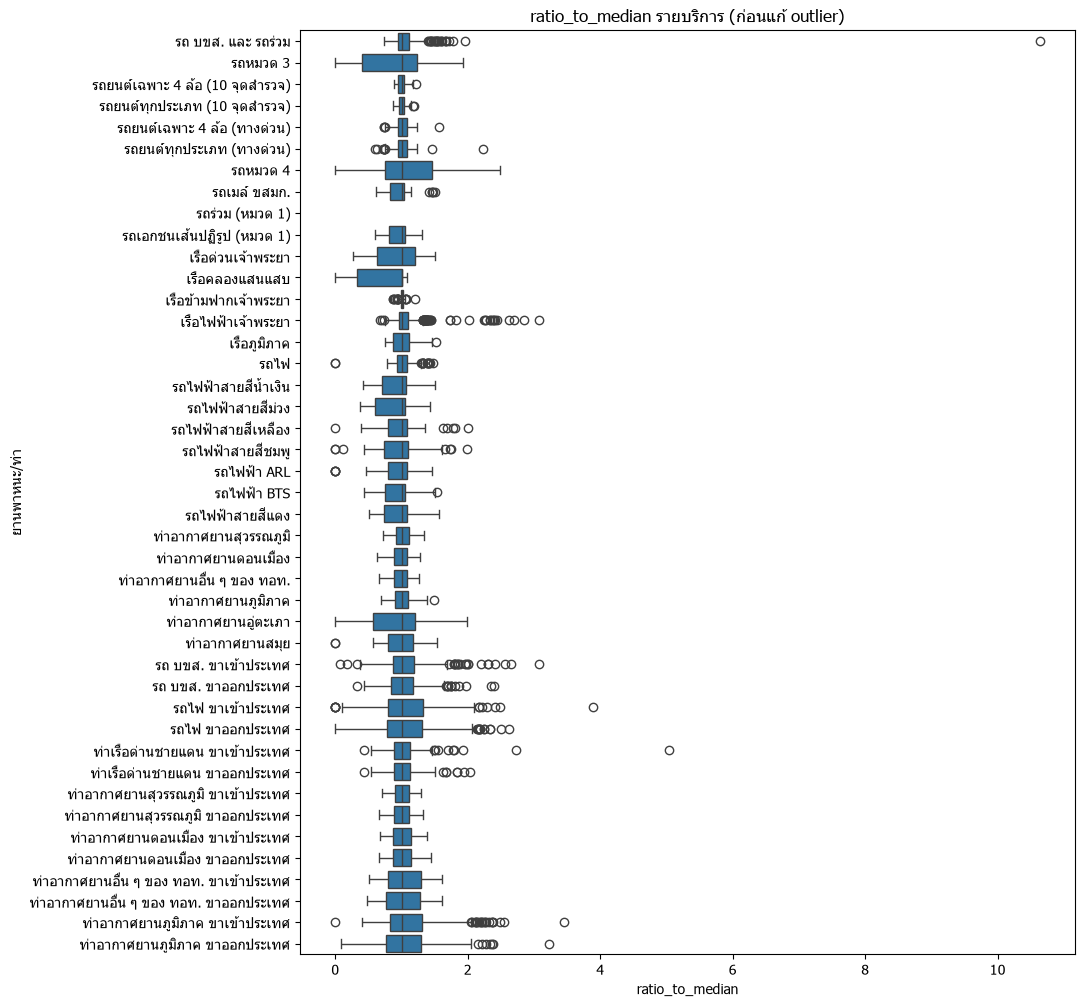

In [10]:
service = df["ยานพาหนะ/ท่า"]

# Q1, Q3, IQR และรั้ว แยกรายบริการ
q1 = df.groupby("ยานพาหนะ/ท่า")["qty"].quantile(0.25)
q3 = df.groupby("ยานพาหนะ/ท่า")["qty"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

# map: นำรั้วของบริการนั้นไปวางให้ทุกแถว แล้วเทียบ
out_mask = (df["qty"] < service.map(lower)) | (df["qty"] > service.map(upper))
print("outlier ทั้งหมด: ", out_mask.sum(), "ค่า")
print("-"*100)

# อัตราส่วนเทียบมัธยฐานของบริการ
median = df.groupby("ยานพาหนะ/ท่า")["qty"].median()
df["ratio_to_median"] = df["qty"] / service.map(median)

# บริการที่มี outlier มากที่สุด 10 อันดับ
display(df[out_mask].groupby("ยานพาหนะ/ท่า").size().sort_values(ascending= False).head(10))
print("-"*100)

# outlier ที่สูงที่สุด 6 อันดับ (เทียบด้วย ratio)
display(df[out_mask].sort_values("ratio_to_median", ascending= False)
        [["ยานพาหนะ/ท่า", "วันที่", "qty", "ratio_to_median"]].head(6).round(2))

# boxplot ของ ratio ทุกบริการ (ก่อนแก้)
plt.figure(figsize=(10, 12))
sns.boxplot(data= df, x= "ratio_to_median", y= "ยานพาหนะ/ท่า")
plt.title("ratio_to_median รายบริการ (ก่อนแก้ outlier)")
plt.show()

- boxplot: รถร่วม (หมวด 1) ไม่มีกล่อง เพราะทุกค่าเป็น NaN ตั้งแต่ 3.2 จึงไม่ใช้วิเคราะห์ ส่วนค่าผิดของ รถ บขส. และ รถร่วม (10.64) ทำให้แกนยืดไปถึง 10 ทั้งที่ค่าอื่นทั้งหมดไม่เกิน 3.9
- บริการที่กล่องกว้าง (รถหมวด 3/4, เรือคลองแสนแสบ, อู่ตะเภา) มีความผันผวนรายวันสูง ซึ่งเกี่ยวข้องกับข้อ 3

In [11]:
check_days = [("รถ บขส. และ รถร่วม", "2025-04-02", "2025-04-08"),
              ("ท่าเรือด่านชายแดน ขาเข้าประเทศ", "2025-09-09", "2025-09-15")]

for name, start, end in check_days:
    near = (service == name) & (df["date"] >= start) & (df["date"] <= end)
    display(df.loc[near, ["ยานพาหนะ/ท่า", "วันที่", "qty", "ratio_to_median"]].round(2))

,ยานพาหนะ/ท่า,วันที่,qty,ratio_to_median
3913,รถ บขส. และ รถร่วม,02/04/2025,91071.0,1.07
3956,รถ บขส. และ รถร่วม,03/04/2025,96162.0,1.13
3999,รถ บขส. และ รถร่วม,04/04/2025,112324.0,1.31
4042,รถ บขส. และ รถร่วม,05/04/2025,908667.0,10.64
4085,รถ บขส. และ รถร่วม,06/04/2025,104713.0,1.23
4128,รถ บขส. และ รถร่วม,07/04/2025,107245.0,1.26
4171,รถ บขส. และ รถร่วม,08/04/2025,107209.0,1.25


,ยานพาหนะ/ท่า,วันที่,qty,ratio_to_median
10826,ท่าเรือด่านชายแดน ขาเข้าประเทศ,09/09/2025,1907.0,0.86
10869,ท่าเรือด่านชายแดน ขาเข้าประเทศ,10/09/2025,2103.0,0.95
10912,ท่าเรือด่านชายแดน ขาเข้าประเทศ,11/09/2025,2087.0,0.94
10955,ท่าเรือด่านชายแดน ขาเข้าประเทศ,12/09/2025,11154.0,5.03
10998,ท่าเรือด่านชายแดน ขาเข้าประเทศ,13/09/2025,2151.0,0.97
11041,ท่าเรือด่านชายแดน ขาเข้าประเทศ,14/09/2025,2293.0,1.03
11084,ท่าเรือด่านชายแดน ขาเข้าประเทศ,15/09/2025,2024.0,0.91


In [12]:
# ยืนยันว่าผิด: outlier ที่สูงกว่าวันปกติ 5 เท่าขึ้นไป (ช่องว่างจากอันดับ 3 ที่ 3.88 และวันรอบข้างปกติ)
error_mask = out_mask & (df["ratio_to_median"] >= 5)

# สถานะตาม W4 สไลด์ 16
df["outlier_status"] = "ปกติ"
df.loc[out_mask, "outlier_status"] = "ยังยืนยันไม่ได้"
df.loc[error_mask, "outlier_status"] = "ยืนยันว่าผิด"
display(df["outlier_status"].value_counts())
print("-"*100)

# เทียบ describe ก่อน/หลังแก้ (ตัวอย่าง รถ บขส. และ รถร่วม)
bus = service == "รถ บขส. และ รถร่วม"
before = df.loc[bus, "qty"].describe()

# ไม่รู้ค่าจริง จึงเปลี่ยนเป็น NaN (ไม่เดาค่า)
df.loc[error_mask, "qty"] = np.nan
df["ratio_to_median"] = df["qty"] / service.map(median)

after = df.loc[bus, "qty"].describe()
display(pd.DataFrame({"ก่อน": before, "หลัง": after}).round(0))
print("ค่าว่างหลังแก้: ", df["qty"].isna().sum())

outlier_status
ปกติ               18447
ยังยืนยันไม่ได้      256
ยืนยันว่าผิด           2
Name: count, dtype: int64

----------------------------------------------------------------------------------------------------


,ก่อน,หลัง
count,433.0,432.0
mean,91754.0,89863.0
std,41974.0,14627.0
min,63186.0,63186.0
25%,80385.0,80373.0
50%,85431.0,85404.0
75%,95461.0,95408.0
max,908667.0,167444.0


ค่าว่างหลังแก้:  1205


- IQR รายบริการพบ outlier 258 ค่า แต่ outlier ไม่ได้แปลว่าผิดเสมอ จึงติดสถานะตามหลักฐาน
- ยืนยันว่าผิด 2 ค่า: รถ บขส. และ รถร่วม 5/4/2025 (908,667 สูงกว่าวันปกติ 10.6 เท่า) และ ท่าเรือด่านชายแดน ขาเข้า 12/9/2025 (11,154 สูงกว่า 5.0 เท่า) วันรอบข้าง ±3 วันปกติทั้งหมด (ratio 0.86–1.31) และค่าถัดไปที่สูงที่สุดคือ 3.88 เท่า มีช่องว่างชัดเจน จึงเปลี่ยนเป็น NaN เพราะไม่รู้ค่าจริง
- ยังยืนยันไม่ได้ 256 ค่า: เก็บค่าไว้ เช่น รถ บขส. ช่วงกลางเดือน เม.ย. สูงต่อเนื่องหลายวัน และ 34 ค่า 0 จาก 3.2 ไม่ cap หรือตัด เพราะข้อ 1 และข้อ 3 ต้องใช้ค่าสูง/ต่ำที่เกิดขึ้นจริง
- ผลกระทบ: รถ บขส. และ รถร่วม std ลดจาก 41,974 เป็น 14,627 ส่วน median แทบไม่เปลี่ยน (85,431 → 85,404)

## 3.4 รถ 4 ล้อ > รถทุกประเภท (ทางด่วน)

*แก้ปัญหาข้อ 9: 5 วันที่รถ 4 ล้อ > รถทุกประเภท ซึ่งขัดกับนิยาม ข้อมูลไม่บอกว่าตัวไหนผิด จึงเปลี่ยนทั้งคู่ของวันนั้นเป็น NaN และทำเครื่องหมายในคอลัมน์ subset_error (AIE315 W6 สไลด์ 30–31, W4 สไลด์ 18)*

ค่าที่แก้ = 5 วัน × 2 บริการ = 10 ค่า → ค่าว่าง = 1,205 + 10 = 1,215

In [13]:
service = df["ยานพาหนะ/ท่า"]
car4_name = "รถยนต์เฉพาะ 4 ล้อ (ทางด่วน)"
all_name = "รถยนต์ทุกประเภท (ทางด่วน)"

# จับคู่ตามวันที่: qty_x = 4 ล้อ, qty_y = ทุกประเภท
car4 = df[service == car4_name][["date", "qty"]]
all_cars = df[service == all_name][["date", "qty"]]
car_pair = pd.merge(car4, all_cars, on= "date", how= "left", validate= "one_to_one")

bad_dates = car_pair.loc[car_pair["qty_x"] > car_pair["qty_y"], "date"]
print("วันที่ขัดกันก่อนแก้: ", len(bad_dates), "วัน")
display(car_pair[car_pair["qty_x"] > car_pair["qty_y"]])
print("-"*100)

# เปลี่ยนเป็น NaN ทั้งคู่ในวันที่ขัดกัน
subset_error = ((service == car4_name) | (service == all_name)) & df["date"].isin(bad_dates)
df["subset_error"] = subset_error
df.loc[subset_error, "qty"] = np.nan
print("ค่าที่เปลี่ยนเป็น NaN: ", subset_error.sum(), "ค่า")

# ตรวจผล: จับคู่ใหม่แล้วนับอีกรอบ
car4 = df[service == car4_name][["date", "qty"]]
all_cars = df[service == all_name][["date", "qty"]]
car_pair_after = pd.merge(car4, all_cars, on= "date", how= "left", validate= "one_to_one")
bad_after = (car_pair_after["qty_x"] > car_pair_after["qty_y"]).sum()
print("วันที่ขัดกันหลังแก้: ", bad_after, "วัน")
print("ค่าว่างหลังแก้: ", df["qty"].isna().sum())

วันที่ขัดกันก่อนแก้:  5 วัน


,date,qty_x,qty_y
0,2025-01-01,1364992.0,979129.0
1,2025-01-02,1286160.0,947189.0
29,2025-01-30,1641282.0,1517654.0
30,2025-01-31,1689391.0,1399387.0
282,2025-10-10,2373044.0,2301447.0


----------------------------------------------------------------------------------------------------
ค่าที่เปลี่ยนเป็น NaN:  10 ค่า
วันที่ขัดกันหลังแก้:  0 วัน
ค่าว่างหลังแก้:  1215


- 5 วันที่ขัดกัน: 1–2 ม.ค. ตัว "ทุกประเภท" ต่ำกว่าวันรอบข้างชัดเจน ส่วน 10 ต.ค. ทั้งคู่สูงผิดปกติ หลักฐานจึงไม่บอกแน่ชัดว่าตัวไหนผิด จึงเปลี่ยนเป็น NaN ทั้งคู่ 10 ค่า หลังแก้เหลือ 0 วันที่ขัดกัน
- ข้อจำกัด: วิธีนี้จับได้เฉพาะวันที่ขัดกับนิยามจริง (สัดส่วน > 1) เช่น 1–2 ก.พ. สัดส่วน 0.85 และ 0.78 ต่ำกว่าปกติ (~0.96) แต่ไม่ขัดนิยาม จึงไม่ได้แก้
- 10 จุดสำรวจไม่มีปัญหานี้ (ผลจาก 2.5)

In [14]:
summary = pd.DataFrame({
    "ปัญหา": ["จำนวนแถว", "แถวซ้ำทุกคอลัมน์", "ชื่อสะกดผิด", "ค่าว่างใน qty",
              "ค่า 0 ใน qty", "outlier ที่ยืนยันว่าผิด", "วันที่ 4 ล้อ > ทุกประเภท"],
    "ก่อนเเก้": [len(df68_raw) + len(df69_raw),
             df_check[raw_cols].duplicated().sum(),
             (df_check["ยานพาหนะ/ท่า"] == old_name).sum(),
             df_check["qty_test"].isna().sum(),
             (df_check["qty_test"] == 0).sum(),
             error_mask.sum(),
             len(bad_dates)],
    "หลังเเก้": [len(df),
             df[raw_cols].duplicated().sum(),
             (df["ยานพาหนะ/ท่า"] == old_name).sum(),
             df["qty"].isna().sum(),
             (df["qty"] == 0).sum(),
             (error_mask & df["qty"].notna()).sum(),
             bad_after]
})
display(summary)

,ปัญหา,ก่อนเเก้,หลังเเก้
0,จำนวนแถว,72450,18705
1,แถวซ้ำทุกคอลัมน์,1,0
2,ชื่อสะกดผิด,435,0
3,ค่าว่างใน qty,444,1215
4,ค่า 0 ใน qty,793,34
5,outlier ที่ยืนยันว่าผิด,2,0
6,วันที่ 4 ล้อ > ทุกประเภท,5,0


# 4. Data Transformation และ Feature Engineering

*สร้าง feature ใหม่จากข้อมูลที่ทำความสะอาดแล้ว เพื่อใช้ตอบโจทย์ทั้ง 3 ข้อ ทุก feature ต้องตรวจผลด้วยการนับหรือคิดมือ (AIE315 W7)*

## 4.1 Feature จากวันที่

*แยก year, month, day_of_week (0 = จันทร์ … 6 = อาทิตย์) และ is_weekend (1 = เสาร์/อาทิตย์) จาก date ใช้ในข้อ 1–3 (AIE315 W7 สไลด์ 13) และแปลงเลขวันเป็นชื่อวันภาษาไทยด้วย map (W5 สไลด์ 18)*

- ปี 2025: 365 = 52 สัปดาห์ + 1 วัน (1 ม.ค. เป็นวันพุธ) → วันหยุด 104 วัน, วันทำงาน 261 วัน
- ปี 2026: 70 วัน = 10 สัปดาห์พอดี → วันหยุด 20 วัน, วันทำงาน 50 วัน

In [15]:
# ดึงส่วนประกอบของวันที่ (date เป็น datetime แล้วจาก 3.1)
df["year"] = df["date"].dt.year                  # ปี ค.ศ. (2025 = 2568, 2026 = 2569)
df["month"] = df["date"].dt.month                # เดือน 1–12
df["day_of_week"] = df["date"].dt.dayofweek      # 0 = จันทร์ ... 6 = อาทิตย์
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)   # 1 = เสาร์/อาทิตย์

# ชื่อวันภาษาไทย ไว้ใช้แสดงในกราฟ
day_th = {0: "จันทร์", 1: "อังคาร", 2: "พุธ", 3: "พฤหัสบดี", 4: "ศุกร์", 5: "เสาร์", 6: "อาทิตย์"}
df["day_name"] = df["day_of_week"].map(day_th)

# ตรวจผล: นับเป็น "วัน" ไม่ใช่ "แถว" (1 วันมี 43 แถว)
days = df.drop_duplicates(subset= "date")
display(days.groupby(["year", "is_weekend"]).size())
print("-"*100)
display(days[["date", "day_name"]].head(3))

C:\Users\MARU\AppData\Local\Temp\ipykernel_14776\1612360157.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["date"].dt.dayofweek      # 0 = จันทร์ ... 6 = อาทิตย์


year  is_weekend
2025  0             261
      1             104
2026  0              50
      1              20
dtype: int64

----------------------------------------------------------------------------------------------------


,date,day_name
0,2025-01-01,พุธ
43,2025-01-02,พฤหัสบดี
86,2025-01-03,ศุกร์


## 4.2 ช่วงเทียบของข้อ 2

*in_q2_window= True เมื่อวันที่อยู่ในช่วง 1 ม.ค.–11 มี.ค. ใช้เทียบปี 2569 กับช่วงเดียวกันของปี 2568*

70 วัน (31 + 28 + 11) × 43 บริการ = 3,010 แถวต่อปี และ 70 วัน = 10 สัปดาห์พอดี ทั้งสองปีจึงมีวันหยุด 20 วันเท่ากัน

In [16]:
# 1 ม.ค.–11 มี.ค.: เดือน 1–2 ทั้งเดือน หรือ เดือน 3 วันที่ไม่เกิน 11
df["in_q2_window"] = (df["month"] < 3) | ((df["month"] == 3) & (df["date"].dt.day <= 11))

display(df[df["in_q2_window"]].groupby("year").size())
print("-"*100)
display(df[df["in_q2_window"]].drop_duplicates(subset= "date").groupby(["year", "is_weekend"]).size())

year
2025    3010
2026    3010
dtype: int64

----------------------------------------------------------------------------------------------------


year  is_weekend
2025  0             50
      1             20
2026  0             50
      1             20
dtype: int64

## 4.3 ทิศทางขาเข้า/ขาออก

*สร้าง direction จากคำว่า "ขาเข้าประเทศ" / "ขาออกประเทศ" ในชื่อบริการ ใช้ในข้อ 3 บริการที่ไม่ใช่ระหว่างประเทศได้ "ไม่ระบุ" (str.contains: AIE315 W5)*

14 บริการระหว่างประเทศ = ขาเข้า 7 + ขาออก 7 → ฝั่งละ 7 × 435 = 3,045 แถว

In [17]:
service = df["ยานพาหนะ/ท่า"]

df["direction"] = "ไม่ระบุ"
df.loc[service.str.contains("ขาเข้าประเทศ", regex= False), "direction"] = "ขาเข้า"
df.loc[service.str.contains("ขาออกประเทศ", regex= False), "direction"] = "ขาออก"

# ตรวจผล: ต้องมีทิศทางเฉพาะการเดินทางระหว่างประเทศ
display(df.groupby(["วัตถุประสงค์", "direction"]).size())
print("-"*100)

# แต่ละรูปแบบมีขาเข้า/ขาออกกี่บริการ และใช้หน่วยอะไร
international = df["direction"] != "ไม่ระบุ"
display(df[international].groupby(["รูปแบบการเดินทาง", "direction"])["ยานพาหนะ/ท่า"].nunique())
print("-"*100)
print("หน่วยของบริการระหว่างประเทศ: ", df.loc[international, "หน่วย"].unique())

วัตถุประสงค์                    direction
การเดินทางภายในจังหวัด/กรุงเทพ  ไม่ระบุ      6960
การเดินทางระหว่างจังหวัด        ไม่ระบุ      5655
การเดินทางระหว่างประเทศ         ขาออก        3045
                                ขาเข้า       3045
dtype: int64

----------------------------------------------------------------------------------------------------


รูปแบบการเดินทาง  direction
ทางถนน            ขาออก        1
                  ขาเข้า       1
ทางน้ำ            ขาออก        1
                  ขาเข้า       1
ทางราง            ขาออก        1
                  ขาเข้า       1
ทางอากาศ          ขาออก        4
                  ขาเข้า       4
Name: ยานพาหนะ/ท่า, dtype: int64

----------------------------------------------------------------------------------------------------
หน่วยของบริการระหว่างประเทศ:  <StringArray>
['คน']
Length: 1, dtype: str


## 4.4 ratio_to_median (ดัชนีเทียบข้ามบริการ)

*ratio_to_median = qty ÷ มัธยฐานของบริการ (1 = วันปกติของบริการนั้น) คำนวณใหม่หลังทำความสะอาดครบ เพราะ 10 ค่าของทางด่วนที่เปลี่ยนเป็น NaN ใน 3.4 ยังมี ratio เก่าค้างอยู่ ทำให้เทียบบริการที่ขนาดต่างกันได้ ใช้ในข้อ 1 และข้อ 3 (AIE315 W7 สไลด์ 15–16)*

แถวที่มี ratio ต้องเท่ากับ 18,705 − 1,215 = 17,490

In [18]:
print("ratio มีค่าแต่ qty ว่าง (ก่อนแก้): ", (df["ratio_to_median"].notna() & df["qty"].isna()).sum())
print("-"*100)

median = df.groupby("ยานพาหนะ/ท่า")["qty"].median()
df["ratio_to_median"] = df["qty"] / service.map(median)

print("ratio มีค่าแต่ qty ว่าง (หลังแก้): ", (df["ratio_to_median"].notna() & df["qty"].isna()).sum())
print("-"*100)
display(df["ratio_to_median"].describe().round(3))

ratio มีค่าแต่ qty ว่าง (ก่อนแก้):  10
----------------------------------------------------------------------------------------------------
ratio มีค่าแต่ qty ว่าง (หลังแก้):  0
----------------------------------------------------------------------------------------------------


count    17490.000
mean         0.988
std          0.263
min          0.000
25%          0.861
50%          1.000
75%          1.099
max          3.883
Name: ratio_to_median, dtype: float64

## สรุปขั้นที่ 4: Feature ที่สร้าง

| Feature | วิธีสร้าง | อ้างอิง | ใช้ในข้อ |
| :--- | :--- | :--- | :---: |
| year, month | dt.year, dt.month | W7 สไลด์ 13 | 1, 2, 3 |
| day_of_week | dt.dayofweek (0 = จันทร์) | W7 สไลด์ 13 | 1 |
| is_weekend | day_of_week ≥ 5 → 1 | W7 สไลด์ 13 | 1 |
| day_name | map เลขวัน → ชื่อวันไทย | W5 สไลด์ 18 | 1 |
| in_q2_window | 1 ม.ค.–11 มี.ค. ของทุกปี | W7 | 2 |
| direction | str.contains "ขาเข้า/ขาออกประเทศ" | W5 | 3 |
| ratio_to_median | qty ÷ มัธยฐานของบริการ | W7 สไลด์ 15–16 | 1, 3 |
| zero_unconfirmed | 0 ที่ยังยืนยันไม่ได้ (3.2) | W4 สไลด์ 16 | 2 |
| outlier_status, subset_error | สถานะจากขั้นที่ 3 | W4 สไลด์ 16 | ตามรอย |

# 5 Export Prepared Dataset

## 5.1 Export Prepared Dataset

*บันทึกข้อมูลที่ทำความสะอาดและสร้าง feature แล้วเป็น outputs/prepared_daily.csv ให้ notebook 02–04 ใช้ ตัดคอลัมน์ที่ซ้ำซ้อน 4 คอลัมน์ (AIE315 W8 สไลด์ 15–17) และตรวจไฟล์หลัง export (W6 สไลด์ 30–31)*

| คอลัมน์ที่ตัด | เหตุผล |
| :--- | :--- |
| วันที่ | ข้อความ ซ้ำกับ date |
| ปริมาณ | ข้อความ ซ้ำกับ qty (ค่าดิบยังอยู่ใน data/) |
| สาธารณะ/ส่วนบุคคล | ซ้ำกับ หน่วย 100% |
| หน่วยงาน | ใช้ตรวจการนับซ้อนแล้ว ไม่ใช้วิเคราะห์ |

In [19]:
# คอลัมน์ที่ส่งต่อ: เวลา → บริการ → ค่า → สถานะ/ตามรอย
keep_cols = ["date", "year", "month", "day_of_week", "day_name", "is_weekend", "in_q2_window",
             "รูปแบบการเดินทาง", "วัตถุประสงค์", "ยานพาหนะ/ท่า", "direction", "หน่วย",
             "qty", "ratio_to_median", "zero_unconfirmed", "outlier_status", "subset_error", "ไฟล์"]

prepared = df[keep_cols].sort_values(["date", "ยานพาหนะ/ท่า"]).reset_index(drop= True)
print("ขนาดก่อน export: ", prepared.shape)

# utf-8-sig ให้ Excel อ่านภาษาไทยได้
prepared.to_csv("../outputs/prepared_daily.csv", index= False, encoding= "utf-8-sig")
print("-"*100)

# ตรวจผล: อ่านกลับมาเทียบ
check = pd.read_csv("../outputs/prepared_daily.csv")
print("ขนาดหลังอ่านกลับ: ", check.shape)
print("qty ว่าง: ", check["qty"].isna().sum(), "| ค่า 0: ", (check["qty"] == 0).sum(),
      "| บริการ: ", check["ยานพาหนะ/ท่า"].nunique())
print("คอลัมน์ตรงกัน: ", check.columns.equals(prepared.columns))
print("qty ตรงกัน: ", check["qty"].equals(prepared["qty"]))
print("-"*100)

# CSV เก็บวันที่เป็นข้อความ ต้องแปลงกลับทุกครั้งที่อ่าน
print("ชนิดของ date หลังอ่านกลับ: ", check["date"].dtype)
check["date"] = pd.to_datetime(check["date"], format= "%Y-%m-%d")
print("ช่วงวันที่: ", check["date"].min(), "ถึง", check["date"].max())

ขนาดก่อน export:  (18705, 18)
----------------------------------------------------------------------------------------------------
ขนาดหลังอ่านกลับ:  (18705, 18)
qty ว่าง:  1215 | ค่า 0:  34 | บริการ:  43
คอลัมน์ตรงกัน:  True
qty ตรงกัน:  True
----------------------------------------------------------------------------------------------------
ชนิดของ date หลังอ่านกลับ:  str
ช่วงวันที่:  2025-01-01 00:00:00 ถึง 2026-03-11 00:00:00
